In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [3]:
root=Path("..")/"Experiment_Results"/"HasilEksperimenTahap2"/"Tahap2A"/"Population"
population_values=[50,100,250,500,1000]

dataframes=[];
for population in population_values:
    population_directory=root/str(population)
    for csv_file in population_directory.rglob("*.csv"):
        df=pd.read_csv(csv_file)
        df["population_folder"]=population
        df["source_path"]=str(csv_file.relative_to(root))

        dataframes.append(df)
if dataframes:
    df_all=pd.concat(dataframes, ignore_index=True)
else:
    df_all=pd.DataFrame()

In [5]:
df_M03=df_all[df_all["model_id"]=="M03"].copy()
summary_M03=(df_M03.groupby(["grid_rows","population", "map_type"], as_index=False).agg(
        mean_cost=("best_cost", "mean"),
        best_run=("best_cost", "min"),
        worst_run=("best_cost", "max"),
        std_cost=("best_cost", "std"),
        total_runs=("best_cost", "count")
    ))
display(summary_M03)

,grid_rows,population,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,50,Cluster,2.523333,2.500000,2.600000,0.043018,30
1,10,50,Maze,3.355556,3.333333,3.500000,0.057624,30
2,10,50,Random,2.607143,2.416667,2.857143,0.167371,60
3,10,100,Cluster,2.523333,2.500000,2.600000,0.043018,30
4,10,100,Maze,3.344444,3.333333,3.500000,0.042285,30
5,10,100,Random,2.586111,2.416667,2.857143,0.153012,60
6,10,250,Cluster,2.500000,2.500000,2.500000,0.000000,30
7,10,250,Maze,3.338889,3.333333,3.500000,0.030429,30
8,10,250,Random,2.576984,2.416667,2.857143,0.153562,60
9,10,500,Cluster,2.516667,2.500000,2.700000,0.046113,30


In [6]:
table_random = (
    summary_M03[summary_M03["map_type"] == "Random"]
    .sort_values("population")
)

display(table_random)
table_maze = (
    summary_M03[summary_M03["map_type"] == "Maze"]
    .sort_values("population")
)

display(table_maze)
table_cluster = (
    summary_M03[summary_M03["map_type"] == "Cluster"]
    .sort_values("population")
)

display(table_cluster)

,grid_rows,population,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
2,10,50,Random,2.607143,2.416667,2.857143,0.167371,60
17,20,50,Random,6.266741,6.025000,6.564103,0.209678,60
32,40,50,Random,6.689976,6.525641,6.950000,0.111953,60
20,20,100,Random,6.260887,6.025000,6.512821,0.213286,60
35,40,100,Random,6.691018,6.512821,6.943750,0.110265,60
5,10,100,Random,2.586111,2.416667,2.857143,0.153012,60
23,20,250,Random,6.248750,6.025000,6.512821,0.220204,60
8,10,250,Random,2.576984,2.416667,2.857143,0.153562,60
38,40,250,Random,6.674618,6.512821,6.906250,0.117614,60
11,10,500,Random,2.614286,2.416667,2.857143,0.158651,60


,grid_rows,population,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
1,10,50,Maze,3.355556,3.333333,3.500000,0.057624,30
16,20,50,Maze,6.811111,6.794872,6.923077,0.026496,30
31,40,50,Maze,6.897241,6.834483,7.172414,0.072994,30
19,20,100,Maze,6.817094,6.794872,6.871795,0.018726,30
34,40,100,Maze,6.901379,6.834483,7.144828,0.071949,30
4,10,100,Maze,3.344444,3.333333,3.500000,0.042285,30
22,20,250,Maze,6.810256,6.794872,6.846154,0.014442,30
7,10,250,Maze,3.338889,3.333333,3.500000,0.030429,30
37,40,250,Maze,6.887126,6.834483,6.958621,0.035142,30
10,10,500,Maze,3.344444,3.333333,3.500000,0.042285,30


,grid_rows,population,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,50,Cluster,2.523333,2.500000,2.600000,0.043018,30
15,20,50,Cluster,4.795495,4.783784,4.837838,0.016921,30
30,40,50,Cluster,5.512473,5.445161,5.658065,0.053166,30
18,20,100,Cluster,4.797297,4.783784,4.837838,0.018440,30
33,40,100,Cluster,5.505161,5.451613,5.664516,0.049978,30
3,10,100,Cluster,2.523333,2.500000,2.600000,0.043018,30
21,20,250,Cluster,4.798198,4.783784,4.837838,0.018417,30
6,10,250,Cluster,2.500000,2.500000,2.500000,0.000000,30
36,40,250,Cluster,5.506882,5.451613,5.729032,0.063906,30
9,10,500,Cluster,2.516667,2.500000,2.700000,0.046113,30


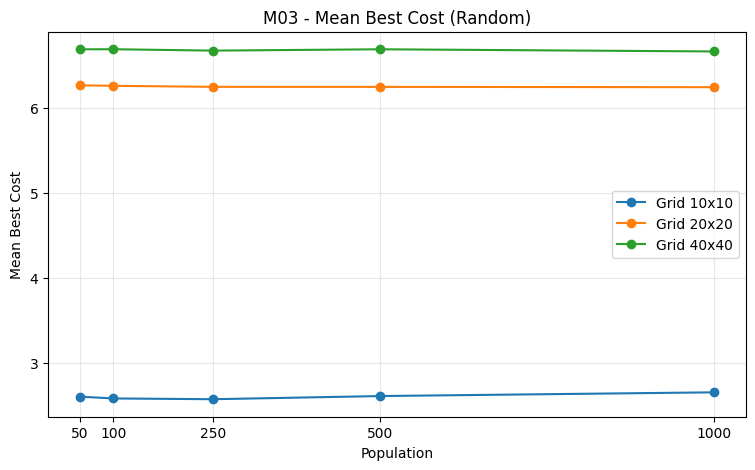

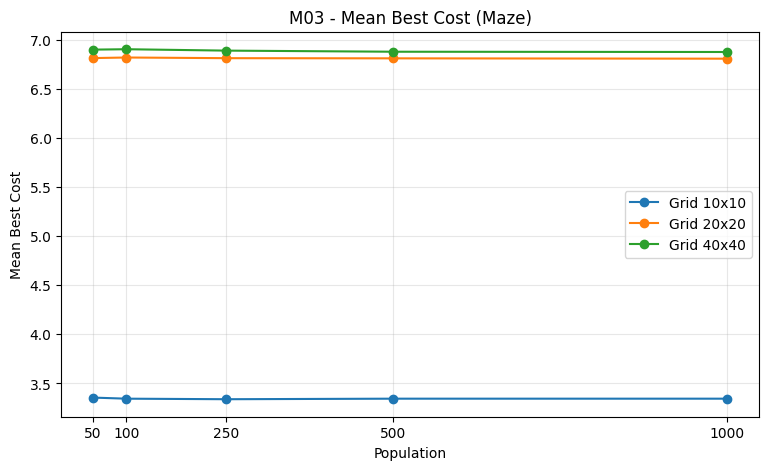

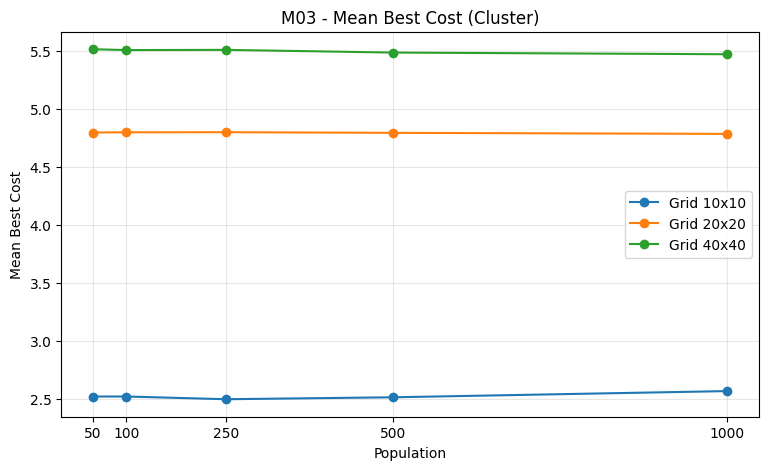

In [14]:
map_types = ["Random", "Maze", "Cluster"]

for map_type in map_types:
    data = summary_M03[
        summary_M03["map_type"] == map_type
    ].copy()

    plt.figure(figsize=(9, 5))

    for grid_rows in sorted(data["grid_rows"].unique()):
        data_size = (
            data[data["grid_rows"] == grid_rows]
            .sort_values("population")
        )

        plt.plot(
            data_size["population"],
            data_size["mean_cost"],
            marker="o",
            label=f"Grid {grid_rows}x{grid_rows}"
        )

    plt.title(f"M03 - Mean Best Cost ({map_type})")
    plt.xlabel("Population")
    plt.ylabel("Mean Best Cost")
    plt.xticks(sorted(data["population"].unique()))
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.show()

In [ ]:
summary_M03["rank_mean_cost"] = (
    summary_M03
    .groupby(["grid_rows", "map_type"])["mean_cost"]
    .rank(method="average", ascending=True)
)
avg_rank_M03 = (
    summary_M03
    .groupby("population", as_index=False)
    .agg(
        avg_rank_mean=("rank_mean_cost", "mean"),
        avg_mean_cost=("mean_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_mean_cost", "count")
    )
    .sort_values(["avg_std_cost"])
)
display(avg_rank_M03)

,population,avg_rank_mean,avg_mean_cost,avg_std_cost,jumlah_kombinasi
2,250,2.555556,5.037967,0.072635,9
3,500,2.555556,5.041648,0.074565,9
4,1000,2.111111,5.045928,0.074694,9
1,100,3.833333,5.047414,0.080106,9
0,50,3.944444,5.051008,0.084358,9


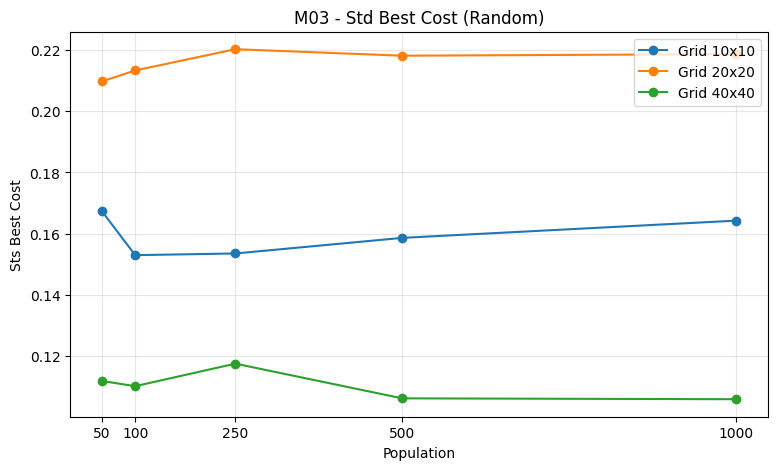

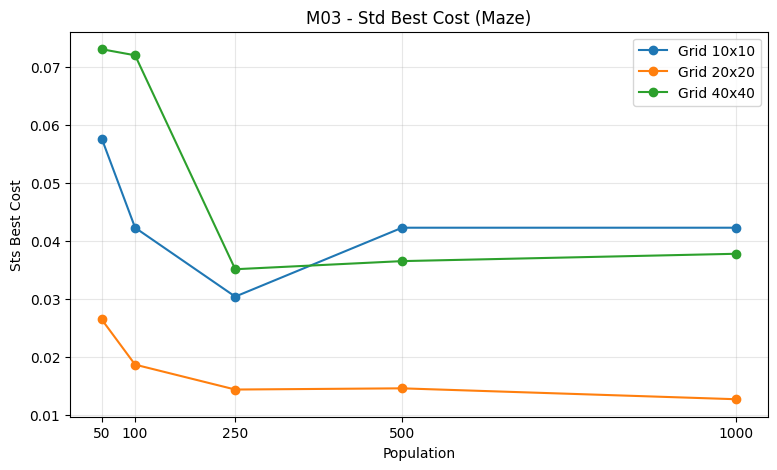

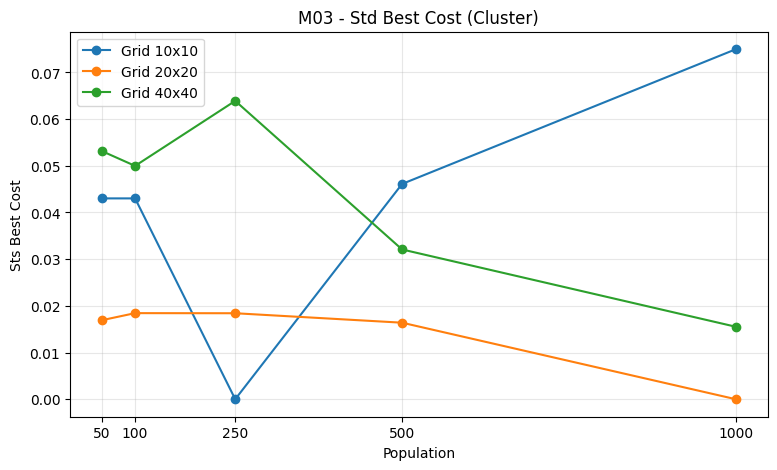

In [ ]:
#std cost
map_types = ["Random", "Maze", "Cluster"]

for map_type in map_types:
    data = summary_M03[
        summary_M03["map_type"] == map_type
    ].copy()

    plt.figure(figsize=(9, 5))

    for grid_rows in sorted(data["grid_rows"].unique()):
        data_size = (
            data[data["grid_rows"] == grid_rows]
            .sort_values("population")
        )

        plt.plot(
            data_size["population"],
            data_size["std_cost"],
            marker="o",
            label=f"Grid {grid_rows}x{grid_rows}"
        )

    plt.title(f"M03 - Std Best Cost ({map_type})")
    plt.xlabel("Population")
    plt.ylabel("Sts Best Cost")
    plt.xticks(sorted(data["population"].unique()))
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.show()

In [12]:
#rank std cost
summary_M03["rank_std_cost"] = (
    summary_M03
    .groupby(["grid_rows", "map_type"])["std_cost"]
    .rank(method="average", ascending=True)
)

avg_rank_M03_std = (
    summary_M03
    .groupby("population", as_index=False)
    .agg(
        avg_rank_std=("rank_std_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_std_cost", "count")
    )
    .sort_values(["avg_rank_std", "avg_std_cost"])
)

print(avg_rank_M03_std)


   population  avg_rank_std  avg_std_cost  jumlah_kombinasi
4        1000      2.444444      0.074694                 9
3         500      2.777778      0.074565                 9
2         250      2.888889      0.072635                 9
1         100      3.055556      0.080106                 9
0          50      3.833333      0.084358                 9


In [13]:
summary_M03_time=(df_M03.groupby(["grid_rows","population", "map_type"], as_index=False).agg(
        mean_execTime=("execution_time_ms", "mean"),
        best_execTime=("execution_time_ms", "min"),
        worst_execTime=("execution_time_ms", "max"),
        std_Time=("execution_time_ms", "std"),
        total_runs=("execution_time_ms", "count")
    ))
display(summary_M03_time)
avg_time_by_population_m03 = (
    summary_M03_time
    .groupby("population", as_index=False)
    .agg(
        avg_execTime=("mean_execTime", "mean"),
        avg_std_time=("std_Time", "mean"),
        jumlah_kombinasi=("mean_execTime", "count")
    )
    .sort_values("avg_execTime")
)
display(avg_time_by_population_m03)
summary_time_pivot = summary_M03_time.pivot(
    index=["grid_rows", "population"],
    columns="map_type",
    values="mean_execTime"
)
display(summary_time_pivot)

avg_time_by_map = (
    summary_M03_time
    .groupby(["map_type", "population"], as_index=False)
    .agg(
        avg_execTime=("mean_execTime", "mean"),
        avg_std_time=("std_Time", "mean"),
        jumlah_kombinasi=("mean_execTime", "count")
    )
    .sort_values(["map_type", "avg_execTime"])
)

print(avg_time_by_map)

,grid_rows,population,map_type,mean_execTime,best_execTime,worst_execTime,std_Time,total_runs
0,10,50,Cluster,6.300000,3,10,1.859737,30
1,10,50,Maze,6.433333,3,17,3.945170,30
2,10,50,Random,13.100000,3,64,18.941211,60
3,10,100,Cluster,10.133333,5,28,5.494407,30
4,10,100,Maze,16.300000,4,82,26.239152,30
5,10,100,Random,9.033333,5,16,2.928334,60
6,10,250,Cluster,12.233333,6,17,2.800041,30
7,10,250,Maze,9.733333,5,17,3.128659,30
8,10,250,Random,20.283333,10,80,16.097259,60
9,10,500,Cluster,27.100000,12,69,16.731861,30


,population,avg_execTime,avg_std_time,jumlah_kombinasi
0,50,291.072222,59.171120,9
1,100,321.929630,73.871717,9
2,250,387.170370,84.988611,9
3,500,580.135185,86.550775,9
4,1000,824.224074,100.036427,9


map_type                  Cluster         Maze       Random
grid_rows population                                       
10        50             6.300000     6.433333    13.100000
          100           10.133333    16.300000     9.033333
          250           12.233333     9.733333    20.283333
          500           27.100000    16.666667    22.033333
          1000          36.666667    37.600000    35.616667
20        50            39.433333    37.000000    39.150000
          100           41.533333    39.300000    45.516667
          250           67.500000    55.633333    65.800000
          500           99.600000    95.833333   109.550000
          1000         197.600000   198.133333   210.250000
40        50           882.233333   686.200000   909.800000
          100          912.366667   738.466667  1084.716667
          250         1027.766667  1064.700000  1160.883333
          500         1518.233333  1783.400000  1548.800000
          1000        2293.433333  2092.266667  2316.450000

   map_type  population  avg_execTime  avg_std_time  jumlah_kombinasi
0   Cluster          50    309.322222     41.708740                 3
1   Cluster         100    321.344444     54.935774                 3
2   Cluster         250    369.166667     77.889573                 3
3   Cluster         500    548.311111     56.165132                 3
4   Cluster        1000    842.566667    122.890607                 3
5      Maze          50    243.211111     51.344844                 3
6      Maze         100    264.688889     67.435652                 3
7      Maze         250    376.688889     97.758937                 3
8      Maze         500    631.966667    109.743854                 3
9      Maze        1000    776.000000    105.545405                 3
10   Random          50    320.683333     84.459775                 3
11   Random         100    379.755556     99.243725                 3
12   Random         250    415.655556     79.317325                 3
13   Random         